# 1. Exploration des avis Allociné

**Objectif du projet** : prédire automatiquement si une critique de film est **positive (1)** ou **négative (0)**, en comparant trois approches (TF-IDF, CamemBERT, LLM).

**Objectif de ce notebook** : *regarder* les données avant de faire du machine learning. C'est la même démarche que l'EDA du Titanic, mais sur du texte.

Exécute chaque cellule avec **Maj + Entrée**. Les cellules marquées **À TOI** sont pour toi.

## 1.1 Charger les données

Les données sont déjà découpées en trois parties (comme ton `train_test_split` du Titanic, mais en 3) :
- **train** (160 000 avis) : pour **entraîner** les modèles ;
- **validation** (20 000) : pour **régler** les modèles (choisir les paramètres) ;
- **test** (20 000) : pour la **note finale**, qu'on ne regarde qu'à la toute fin.

Pourquoi trois et pas deux ? Si on règle les paramètres en regardant le test, on finit par « tricher » sans le vouloir : le modèle est optimisé pour ce test-là, et la note devient trop optimiste.

In [38]:
import pandas as pd

train = pd.read_parquet("data/train.parquet")
val = pd.read_parquet("data/validation.parquet")
test = pd.read_parquet("data/test.parquet")

print(train.shape, val.shape, test.shape)
train.head()

(160000, 2) (20000, 2) (20000, 2)


,review,label
0,Si vous cherchez du cinéma abrutissant à tous ...,0
1,"Trash, re-trash et re-re-trash...! Une horreur...",0
2,"Et si, dans les 5 premières minutes du film, l...",0
3,Mon dieu ! Quelle métaphore filée ! Je suis ab...,0
4,"Premier film de la saga Kozure Okami, ""Le Sabr...",1


## 1.2 Lire quelques avis

En NLP, **lire des exemples** est indispensable : les chiffres ne disent pas tout. On affiche 3 avis positifs et 3 négatifs tirés au hasard.

`random_state=42` fixe le hasard : tu obtiendras les mêmes avis à chaque exécution (reproductibilité).

In [39]:
for label, nom in [(1, "POSITIF"), (0, "NÉGATIF")]:
    print(f"===== {nom} =====")
    for avis in train[train["label"] == label]["review"].sample(3, random_state=42):
        print("-", avis[:300], "\n")

===== POSITIF =====
- Dino risi réussit une belle réalisation bien aidé par ses acteurs dont Peter Baldwin et Mylène Démongeot excellents. Malgré un scénario romantique plutôt léger voilà un film très agréable à visionner et un peu inhabituel dans son déroulement. 

- Je suis resté dubitatif pendant les trois premiers quarts d'heure, d'autant plus que je n'aime pas du tout Pierre Niney auquel je trouve toujours le même jeu. mais ELLE...Paula Beer....quelle actrice...et quand le film bascule enfin, quand on connait les raisons de la présence de Frantz...quel film. 

- Film sympathique empreint de bons sentiments. Les caractères sont intéressants et la réalisation très bonne. C'est une réflexion sur l'histoire et la morale... 

===== NÉGATIF =====
- Malgré une scène d'entrée superbe, la mise en scène originale et la présence de Francois Damien qui est toujours hilarant et bien sur celle de j-c, ce film m'a decu. Il ne se passe pas grand chose, et j'ai fini par m'ennuyer. 

- Le pictural 

## 1.3 Les classes sont-elles équilibrées ?

Question essentielle avant tout modèle. Au Titanic, seuls 38 % des passagers avaient survécu : un modèle qui répond toujours « mort » aurait déjà 62 % d'accuracy sans rien apprendre.

Ici, si on a 50 % / 50 %, un modèle « bête » (qui répond toujours pareil) aurait **50 %**. C'est le plancher à battre.

In [40]:
train["label"].value_counts(normalize=True)

label
1    0.503669
0    0.496331
Name: proportion, dtype: float64

## 1.4 À TOI : la longueur des avis

**But** : savoir si les avis sont courts ou longs, et si les avis négatifs sont plus longs que les positifs (ou l'inverse). Ça nous servira pour CamemBERT, qui ne peut lire qu'un nombre limité de mots.

**Exercice** :
1. Crée une colonne `nb_mots` qui contient le nombre de mots de chaque avis.
2. Affiche la moyenne et la médiane de `nb_mots` **par label**.

**Indices** :
- `train["review"].str.split()` découpe chaque avis en liste de mots ;
- `.str.len()` donne la longueur de chaque liste ;
- `train.groupby("label")["nb_mots"].agg(["mean", "median"])`.

In [41]:
# À TOI : crée la colonne nb_mots
train["nb_mots"]=[len(i) for i in train["review"].str.split()]
print(train["nb_mots"])

0         178
1         251
2         100
3         352
4          32
         ... 
159995     12
159996     50
159997    123
159998     31
159999     61
Name: nb_mots, Length: 160000, dtype: int64


In [42]:
# À TOI : moyenne et médiane par label
train.groupby("label")["nb_mots"].agg(["mean","median"])

,mean,median
label,,
0,87.517711,64.0
1,95.030030,69.0


## 1.5 À TOI : visualiser

Trace l'histogramme de `nb_mots` (avec `plt.hist` ou `sns.histplot`, comme au Titanic). Limite l'axe à 0-600 mots pour y voir clair : `plt.xlim(0, 600)`.

**Question** : la distribution est-elle symétrique ? Quel est l'avis le plus long (`train["nb_mots"].max()`) ?

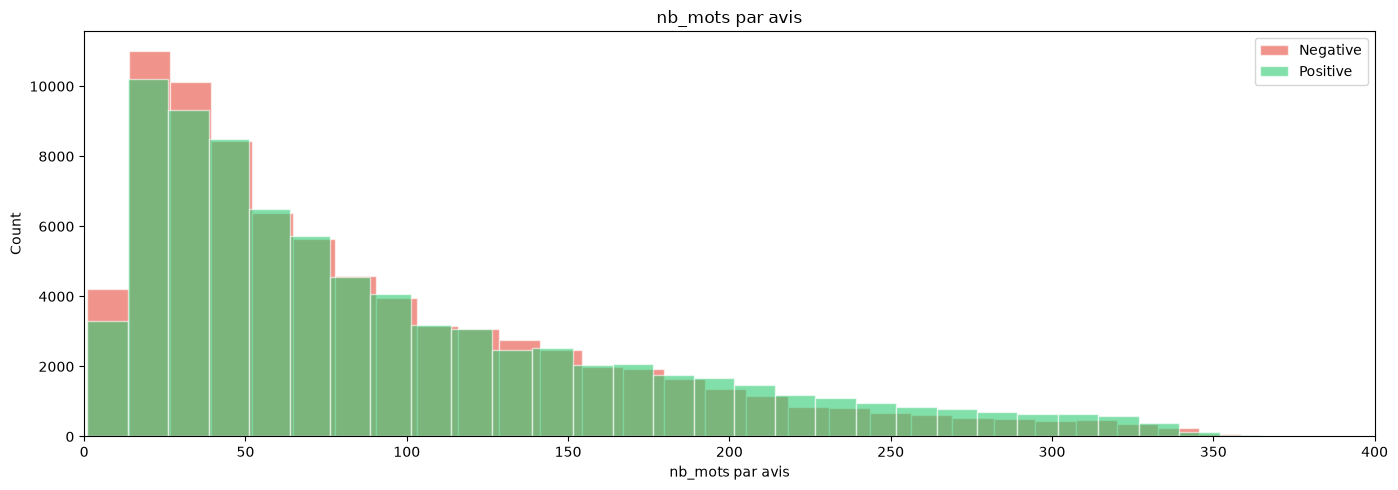

384


In [43]:
import matplotlib.pyplot as plt

# À TOI

fig, axes = plt.subplots(1, 1, figsize=(14, 5))

# Overlapping histograms
axes.hist(train[train["label"] == 0]["nb_mots"].dropna(), bins=30, alpha=0.6,
             color="#e74c3c", label="Negative", edgecolor="white")
axes.hist(train[train["label"] == 1]["nb_mots"].dropna(), bins=30, alpha=0.6,
              color="#2ecc71", label="Positive", edgecolor="white")
axes.set_title("nb_mots par avis")
axes.set_xlabel("nb_mots par avis")
axes.set_ylabel("Count")
axes.legend()
plt.tight_layout()
axes.set_xlim(0, 400)
plt.show()

print(train["nb_mots"].max())

Non la distribution n'est pas symetrique.L'avis le plus long est:384

## 1.6 À TOI : trouver les avis difficiles

Les modèles se tromperont surtout sur certains avis. Lis des avis au hasard (change le `random_state` pour en voir d'autres) et **trouve au moins 2 avis « pièges »**, par exemple :
- de l'**ironie** (« Génial, 2 heures de ma vie perdues ») ;
- un avis **mitigé** (« acteurs excellents mais scénario nul ») ;
- une **négation** (« pas mauvais du tout »).

Copie-les dans la cellule de texte en dessous. On les réutilisera à l'étape 4 pour voir quel modèle s'en sort le mieux.

In [ ]:
train["review"].sample(10, random_state=5).tolist()
pieges=train[((train["label"]==0) & (train["review"].str.contains("génial",case=False))) ]
pieges2=train[((train["label"]==1) & (train["review"].str.contains("pas mauvais",case=False))) ]
courts = pieges2[pieges2["review"].str.len() < 300]
print(len(pieges))
courts["review"].tolist()
pieges["review"].head(5).tolist()

788


["Très bon film ! seul soucis moins bien que le premier du au choix du casting avec les deux grand père qui casse complètement le rythme du film ça deviens limite chiant et ennuyant ! mais dans l'ensemble pas mauvais ! vivement le trois ;)",
 'Film pas mauvais, qui se laisse regarder. Très belle performance de Wahlberg pas habitué à jouer ce genre de rôle et qui réussit son pari.',
 "malgrès sa photographie un peu floue et téléfilmesque! Ce film est efficace. On ressent le cruel manque de budget mais on ne va pas se priver de dire que ce film n'est pas mauvais! Et je mets 4 parce que c'est mon Van Damme!!",
 "Un bon film d'aventure avec de bon acteurs et un scénario pas mauvais. Il a mal viellit, mais pour l'époque c'est très bien fait !",
 "Ce film est un 'blues-movie' vraiment poignant. Christina Ricci & Samuel Lee Jackson forment un duo sensationnel. Et même les quelques apparations de Justin Timberlake ne passent pas inaperçu tant ce chanteur n'est pas mauvais acteur. A voir absolu

**Mes avis pièges** (double-clique ici pour écrire) :

1.  "Après avoir réussi à mêler film horreur et teen-movie avec le génial Destination finale, le réalisateur James Wong s'est embarqué sous les sirènes d'Hollywood dans un film de science-fiction bourré d'action et d'effets spéciaux. Sur le papelard, The One avait l'air plutôt intéressant avec cette histoire de combat entre personnages de plusieurs dimensions parallèles. Et puis voir Jet Li dans un double rôle était une idée alléchante pour les fans de la star asiatique. En somme, The One promettait un bon film d'action science-fictionnel bourré d'affrontements câblés et d'effets visuels Matrixiens. Verdict : c'est sympa, c'est marrant, c'est bien foutu mais c'est hélas aussi très lourd. Tournant en rond au bout d'une vingtaine de minutes, le long-métrage s'avère très répétitif et surtout très peu captivant au final, le scénario n'arrivant jamais à aller plus loin que le bout de son nez. Quant au casting, c'est également peu convaincant... Jet Li peine à convaincre dans son double rôle de gentil paumé et de méchant diabolique tandis que son comparse de fortune Jason Statham (Ghosts of Mars) se régale à faire le big boy qui flingue tout sur son passage. S'ajoutent également au casting le polyvalent Delroy Lindo et la sexy Carla Gugino, campant respectivement le traqueur du bad guy et la comparse du héros. The One est donc une série B tout ce qu'il y a de plus banale où scènes d'action filmées au ralenti, effets visuels à outrance et musique rock omniprésente se fracassent constamment dans un gros bordel pas toujours digérable. Et si le film confirme une belle place dans le cinéma d'action pour Jason Statham, il nous fait amèrement regretter le passage Outre-Atlantique d'un Jet Li confiné aux rôles indigestes voire nanardesques.",

explication: Ici genial etait dans le sujet de parler de a destination finale mais en gros le film etait trop repettitf rt donc dans un long avis comme ca on peut pas deduire directement si geniale impliquait que l'avis est positif

2. 'Film pas mauvais, qui se laisse regarder. Très belle performance de Wahlberg pas habitué à jouer ce genre de rôle et qui réussit son pari.',

explication: pour le cas de la negation il suffit que l'avis ne soit pas trop long pour en deduire que l'avis est plutot positive 
